<a href="https://colab.research.google.com/github/lovkush7/NLP--P/blob/main/Annpassed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
path ="/content/drive/MyDrive/ann_student_performance_practice.csv"

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix , classification_report
import tensorflow as tf
from tensorflow.keras.models import  Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout


In [6]:
df = pd.read_csv(path)

In [7]:
df.head()

,StudyHoursPerDay,AttendancePercentage,PreviousExamScore,SleepHoursPerDay,AssignmentScore,ClassParticipation,InternetAccess,ExtracurricularHours,DailyScreenTimeHours,FamilySupportLevel,Passed
0,4.05,96.99,68.38,7.12,67.04,9,1,0.52,5.36,2,1
1,1.63,90.25,64.20,5.66,72.96,8,1,1.50,1.84,5,1
2,4.85,100.00,77.96,7.12,52.15,3,1,1.86,3.37,3,1
3,5.19,63.43,74.10,5.62,49.80,3,1,0.96,3.28,2,0
4,0.00,78.82,20.21,8.42,74.92,10,1,2.57,3.14,3,0


In [9]:
df.shape

(3000, 11)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   StudyHoursPerDay      3000 non-null   float64
 1   AttendancePercentage  3000 non-null   float64
 2   PreviousExamScore     3000 non-null   float64
 3   SleepHoursPerDay      3000 non-null   float64
 4   AssignmentScore       3000 non-null   float64
 5   ClassParticipation    3000 non-null   int64  
 6   InternetAccess        3000 non-null   int64  
 7   ExtracurricularHours  3000 non-null   float64
 8   DailyScreenTimeHours  3000 non-null   float64
 9   FamilySupportLevel    3000 non-null   int64  
 10  Passed                3000 non-null   int64  
dtypes: float64(7), int64(4)
memory usage: 257.9 KB


In [11]:
df.isnull().sum()

,0
StudyHoursPerDay,0
AttendancePercentage,0
PreviousExamScore,0
SleepHoursPerDay,0
AssignmentScore,0
ClassParticipation,0
InternetAccess,0
ExtracurricularHours,0
DailyScreenTimeHours,0
FamilySupportLevel,0


In [12]:
df.duplicated().sum()

np.int64(0)

<Axes: >

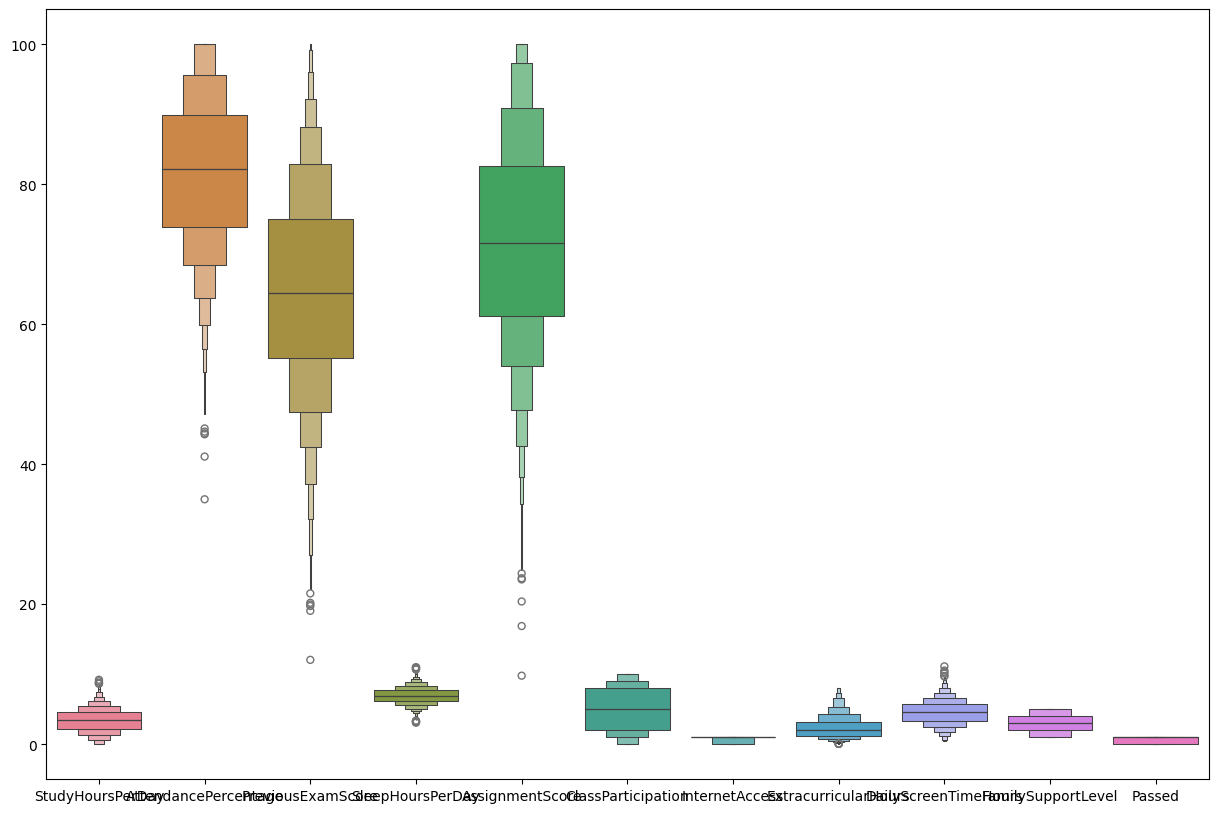

In [16]:
plt.figure(figsize=(15,10))
sns.boxenplot( data=df)

<Figure size 1500x1000 with 0 Axes>

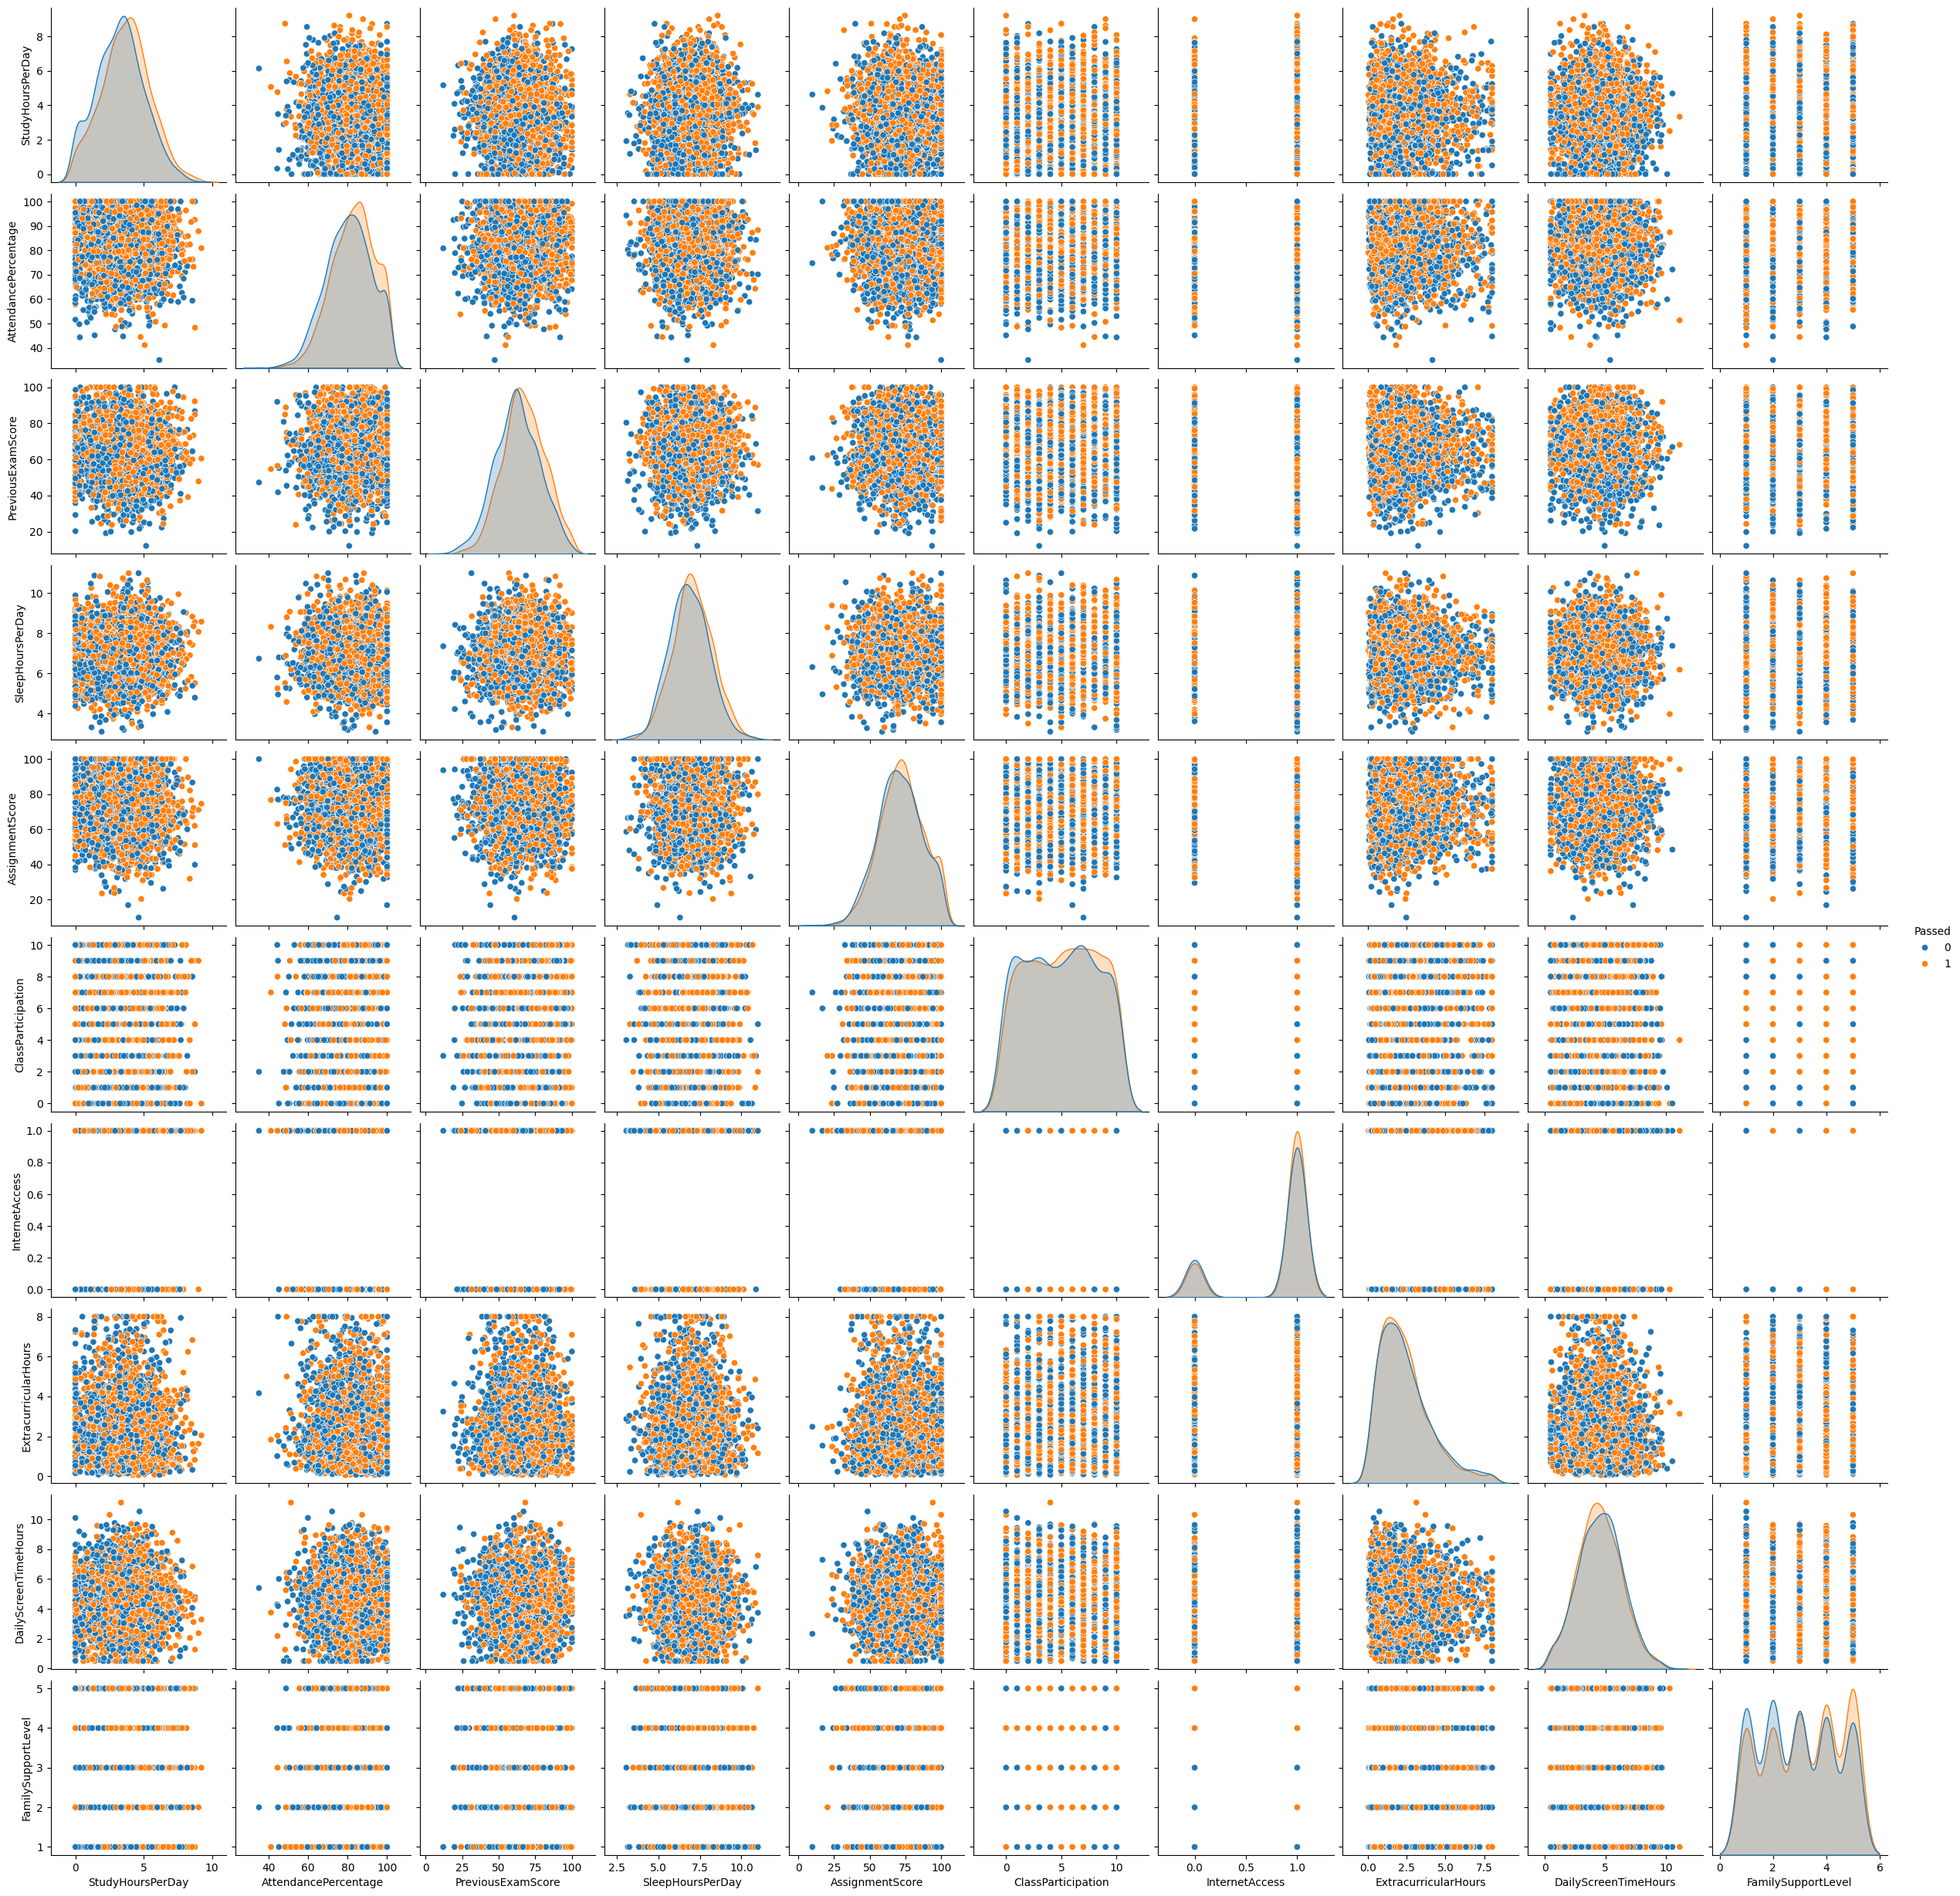

In [18]:
plt.figure(figsize=(15,10))

sns.pairplot(df, hue='Passed')

In [19]:
num_col = df.select_dtypes(include=np.number).columns

for col in num_col:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 -Q1

  lower_bound = Q1 - 1.5*IQR
  upper_bound = Q3 + 1.5*IQR

outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
df[col][outliers] = df[col].median()

print(f"{col}: {outliers} outliers")


Passed: 0 outliers


In [22]:
df.head()

,StudyHoursPerDay,AttendancePercentage,PreviousExamScore,SleepHoursPerDay,AssignmentScore,ClassParticipation,InternetAccess,ExtracurricularHours,DailyScreenTimeHours,FamilySupportLevel,Passed
0,4.05,96.99,68.38,7.12,67.04,9,1,0.52,5.36,2,1
1,1.63,90.25,64.20,5.66,72.96,8,1,1.50,1.84,5,1
2,4.85,100.00,77.96,7.12,52.15,3,1,1.86,3.37,3,1
3,5.19,63.43,74.10,5.62,49.80,3,1,0.96,3.28,2,0
4,0.00,78.82,20.21,8.42,74.92,10,1,2.57,3.14,3,0


In [26]:
df["InternetAccess"].value_counts()

,count
InternetAccess,
1,2446
0,554


In [23]:
X = df.drop("Passed", axis=1)
y = df["Passed"]



In [25]:
X

,StudyHoursPerDay,AttendancePercentage,PreviousExamScore,SleepHoursPerDay,AssignmentScore,ClassParticipation,InternetAccess,ExtracurricularHours,DailyScreenTimeHours,FamilySupportLevel
0,4.05,96.99,68.38,7.12,67.04,9,1,0.52,5.36,2
1,1.63,90.25,64.20,5.66,72.96,8,1,1.50,1.84,5
2,4.85,100.00,77.96,7.12,52.15,3,1,1.86,3.37,3
3,5.19,63.43,74.10,5.62,49.80,3,1,0.96,3.28,2
4,0.00,78.82,20.21,8.42,74.92,10,1,2.57,3.14,3
...,...,...,...,...,...,...,...,...,...,...
2995,2.12,64.36,78.44,7.34,78.71,7,1,2.08,5.63,1
2996,1.32,84.69,40.37,6.85,71.90,2,1,2.48,4.29,5
2997,7.70,100.00,40.97,8.00,52.53,5,1,3.64,6.16,3
2998,4.98,84.44,86.56,5.88,56.17,4,1,3.14,2.21,2


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y)

In [28]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [40]:
model = Sequential([
    Dense(16, input_dim=X_train.shape[1], activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

In [42]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [43]:
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2 , verbose=1 )

Epoch 1/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.4766 - loss: 0.7219 - val_accuracy: 0.4479 - val_loss: 0.7204
Epoch 2/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5115 - loss: 0.6972 - val_accuracy: 0.5021 - val_loss: 0.7030
Epoch 3/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5406 - loss: 0.6850 - val_accuracy: 0.5292 - val_loss: 0.6931
Epoch 4/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5625 - loss: 0.6777 - val_accuracy: 0.5583 - val_loss: 0.6879
Epoch 5/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5724 - loss: 0.6732 - val_accuracy: 0.5625 - val_loss: 0.6848
Epoch 6/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5839 - loss: 0.6692 - val_accuracy: 0.5750 - val_loss: 0.6818
Epoch 7/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5891 - loss: 0.6665 - val_accuracy: 0.5854 - val_loss: 0.6798
Epoch 8/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5969 - loss: 0.6649 - val_accuracy: 0.5854 - 

In [45]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {loss}")
print(f"Test Accuracy: {accuracy}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5633 - loss: 0.6907 
Test Loss: 0.690659761428833
Test Accuracy: 0.5633333325386047


In [46]:
import pandas as pd

new_student = pd.DataFrame([{
    "StudyHoursPerDay": 5.5,
    "AttendancePercentage": 90,
    "PreviousExamScore": 75,
    "SleepHoursPerDay": 7,
    "AssignmentScore": 85,
    "ClassParticipation": 8,
    "InternetAccess": 1,
    "ExtracurricularHours": 2,
    "DailyScreenTimeHours": 3,
    "FamilySupportLevel": 4
}])

In [48]:
def predict_student(data):

    new_data = pd.DataFrame([data])

    scaled_data = scaler.transform(new_data)

    probability = model.predict(
        scaled_data,
        verbose=0
    )[0][0]

    result = "PASS" if probability >= 0.5 else "FAIL"

    return {
        "prediction": result,
        "pass_probability": round(float(probability), 4)
    }

In [50]:
student = {
    "StudyHoursPerDay": 1,
    "AttendancePercentage": 55,
    "PreviousExamScore": 20,
    "SleepHoursPerDay": 6,
    "AssignmentScore": 90,
    "ClassParticipation": 9,
    "InternetAccess": 1,
    "ExtracurricularHours": 12,
    "DailyScreenTimeHours": 3,
    "FamilySupportLevel": 5
}

print(predict_student(student))

{'prediction': 'FAIL', 'pass_probability': 0.1547}
